# 01 · Data collection

Harvests metadata for every arXiv paper first submitted in the last `YEARS_BACK` years to **cs.CV** or
**cs.CL**, and writes it to `data/papers.jsonl` (one paper per line: title, abstract, authors,
categories, dates, URL).

**Source.** arXiv OAI-PMH (`oaipmh.arxiv.org/oai`), the official bulk-metadata interface (free, no API
key). Requests are scoped by set (`cs:cs:CV`, `cs:cs:CL`) and datestamp window, and paged with
resumption tokens. The search API (`export.arxiv.org/api/query`) is unsuitable at this scale: paging
becomes slow and unreliable beyond ~10k results.

**Submission dates.** Neither OAI date gives the v1 submission date:
- `from` / `until` filter on the *datestamp* (last metadata change), so older papers with new versions are included.
- `<created>` is the date of the *latest* version (e.g. `2509.22630`: v1 in Sep 2025, `<created>` 2026-04-24).

New-style IDs (`YYMM.NNNNN`) encode the month of v1, so `submitted` is derived from the ID and used for
filtering. Every paper submitted after `START_DATE` has a datestamp after `START_DATE`, so harvesting
all datestamp windows from `START_DATE` onward is complete.

In [1]:
import json
import re
import time
import xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import timedelta

import pandas as pd
import requests
from tqdm.auto import tqdm

from common import *

print(f"Categories : {CATEGORIES}")
print(f"Date range : {START_DATE} -> {END_DATE}")
print(f"Output     : {PAPERS_PATH}")

Categories : ['cs.CV', 'cs.CL']
Date range : 2024-10-31 -> 2026-10-31
Output     : data/papers.jsonl


## Weekly windows
The date range is split into one-week windows (~800 cs.CV records each, usually a single response),
which are harvested in parallel and retried independently.

In [2]:
def weekly_windows(start, end):
    windows, cur = [], start
    while cur <= end:
        nxt = min(cur + timedelta(days=6), end)
        windows.append((cur.isoformat(), nxt.isoformat()))
        cur = nxt + timedelta(days=1)
    return windows

WINDOWS = weekly_windows(START_DATE, END_DATE)
OAI_SETS = [f"cs:cs:{c.split('.')[1]}" for c in CATEGORIES]   # 'cs.CV' -> OAI set spec 'cs:cs:CV'
JOBS = [(s, w) for s in OAI_SETS for w in WINDOWS]
print(f"{len(WINDOWS)} weekly windows x {len(OAI_SETS)} sets = {len(JOBS)} harvest jobs")
print("example job:", JOBS[0])

105 weekly windows x 2 sets = 210 harvest jobs
example job: ('cs:cs:CV', ('2024-10-31', '2024-11-06'))


## Record parsing
Extracts the fields used downstream from each `<arXiv>` metadata block and normalises whitespace
(abstracts contain hard line breaks from their LaTeX sources).

In [3]:
NS = {"oai": "http://www.openarchives.org/OAI/2.0/", "ax": "http://arxiv.org/OAI/arXiv/"}

def clean(text):
    return " ".join((text or "").split())

def submitted_month(arxiv_id):
    """'2509.22630' -> '2025-09-01' (v1 submission month). Old-style IDs ('cs/0501001') -> None."""
    m = re.match(r"^(\d{2})(\d{2})\.\d{4,5}$", arxiv_id)
    return f"20{m.group(1)}-{m.group(2)}-01" if m else None

def parse_record(rec):
    meta = rec.find("oai:metadata/ax:arXiv", NS)
    if meta is None:                                 # deleted records have no metadata
        return None
    get = lambda tag: clean(meta.findtext(f"ax:{tag}", default="", namespaces=NS))
    authors = []
    for a in meta.findall("ax:authors/ax:author", NS):
        name = " ".join(filter(None, [clean(a.findtext("ax:forenames", "", NS)),
                                      clean(a.findtext("ax:keyname", "", NS))]))
        authors.append(name)
    categories = get("categories").split()
    return {
        "arxiv_id": get("id"),
        "title": get("title"),
        "abstract": get("abstract"),
        "authors": authors,
        "categories": categories,
        "primary_category": categories[0] if categories else "",
        "submitted": submitted_month(get("id")),      # v1 submission month (from the ID)
        "latest_version": get("created"),             # date of the most recent version
        "updated": get("updated") or get("created"),  # last metadata change, used for de-dup
        "doi": get("doi"),
        "url": f"https://arxiv.org/abs/{get('id')}",
    }

## Harvesting a window
- Follows resumption tokens until the window is exhausted.
- Honours `HTTP 503` + `Retry-After` (arXiv rate limiting).
- Treats `noRecordsMatch` (an empty window) as an empty result.

In [4]:
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "ArxivSage-research-harvester/0.1"

def oai_get(params, max_tries=8):
    for attempt in range(max_tries):
        try:
            r = SESSION.get(OAI_URL, params=params, timeout=120)
        except requests.RequestException:
            time.sleep(5 * (attempt + 1)); continue
        if r.status_code == 503:
            time.sleep(int(r.headers.get("Retry-After", 10))); continue
        if r.ok:
            return ET.fromstring(r.content)
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"OAI request failed after {max_tries} tries: {params}")

def harvest_job(oai_set, window):
    params = {"verb": "ListRecords", "metadataPrefix": "arXiv",
              "set": oai_set, "from": window[0], "until": window[1]}
    papers = []
    while True:
        root = oai_get(params)
        err = root.find("oai:error", NS)
        if err is not None:
            if err.get("code") == "noRecordsMatch":
                break
            raise RuntimeError(f"OAI error {err.get('code')}: {err.text}")
        for rec in root.iterfind("oai:ListRecords/oai:record", NS):
            p = parse_record(rec)
            if p:
                papers.append(p)
        token = root.find("oai:ListRecords/oai:resumptionToken", NS)
        if token is None or not (token.text or "").strip():
            break
        params = {"verb": "ListRecords", "resumptionToken": token.text.strip()}
    return papers

# quick sanity check on a single week
sample = harvest_job(*JOBS[0])
print(len(sample), "records in", JOBS[0])
print(json.dumps(sample[0], indent=2)[:900])

735 records in ('cs:cs:CV', ('2024-10-31', '2024-11-06'))
{
  "arxiv_id": "2003.08162",
  "title": "3D Crowd Counting via Geometric Attention-guided Multi-View Fusion",
  "abstract": "Recently multi-view crowd counting using deep neural networks has been proposed to enable counting in large and wide scenes using multiple cameras. The current methods project the camera-view features to the average-height plane of the 3D world, and then fuse the projected multi-view features to predict a 2D scene-level density map on the ground (i.e., birds-eye view). Unlike the previous research, we consider the variable height of the people in the 3D world and propose to solve the multi-view crowd counting task through 3D feature fusion with 3D scene-level density maps, instead of the 2D density map on the ground plane. Compared to 2D fusion, the 3D fusion extracts more information of the people along the z-dimension (height), which helps to address the scale v


## Harvest, filter, de-duplicate
- 4 worker threads (~8 min for two years of both categories).
- Parsed records are cached in `data/raw_records.jsonl`; `FORCE_REHARVEST = True` downloads them again.
- Keeps records with `submitted >= START_DATE` that carry cs.CV or cs.CL.
- Cross-listed or repeatedly updated papers occur more than once; the copy with the latest `updated` date is kept.

In [5]:
RAW_PATH = DATA_DIR / "raw_records.jsonl"
FORCE_REHARVEST = False

if RAW_PATH.exists() and not FORCE_REHARVEST:
    raw = [json.loads(line) for line in open(RAW_PATH)]
    print(f"loaded {len(raw):,} cached raw records from {RAW_PATH.name}")
else:
    raw = []
    with ThreadPoolExecutor(max_workers=4) as pool:
        futures = {pool.submit(harvest_job, s, w): (s, w) for s, w in JOBS}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="harvesting"):
            raw.extend(fut.result())
    with open(RAW_PATH, "w") as f:
        for p in raw:
            f.write(json.dumps(p, ensure_ascii=False) + "\n")
    print(f"harvested {len(raw):,} raw records -> {RAW_PATH.name}")

papers = {}
for p in raw:
    if not p["submitted"] or p["submitted"] < START_DATE.isoformat():
        continue                                      # old paper that merely got a new version
    if not set(p["categories"]) & set(CATEGORIES):
        continue
    if len(p["abstract"].split()) < 20:               # withdrawn / empty abstracts
        continue
    old = papers.get(p["arxiv_id"])
    if old is None or p["updated"] > old["updated"]:
        papers[p["arxiv_id"]] = p

print(f"unique papers kept    : {len(papers):,}")

loaded 134,308 cached raw records from raw_records.jsonl
unique papers kept    : 122,346


## Output
Writes `data/papers.jsonl` and summarises the corpus.

In [6]:
with open(PAPERS_PATH, "w") as f:
    for p in sorted(papers.values(), key=lambda p: p["arxiv_id"]):
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
print(f"saved {PAPERS_PATH}  ({PAPERS_PATH.stat().st_size / 1e6:.1f} MB)")

df = pd.read_json(PAPERS_PATH, lines=True, dtype={"arxiv_id": str, "submitted": str})
df["abstract_words"] = df["abstract"].str.split().str.len()
df["in_CV"] = df["categories"].apply(lambda c: "cs.CV" in c)
df["in_CL"] = df["categories"].apply(lambda c: "cs.CL" in c)
print("\npapers in cs.CV :", int(df.in_CV.sum()))
print("papers in cs.CL :", int(df.in_CL.sum()))
print("in both         :", int((df.in_CV & df.in_CL).sum()))
print("\nabstract length (words):")
print(df["abstract_words"].describe().round(1).to_string())

saved data/papers.jsonl  (221.8 MB)

papers in cs.CV : 74295
papers in cs.CL : 51680
in both         : 3629

abstract length (words):
count    122346.0
mean        181.1
std          40.1
min          20.0
25%         153.0
50%         180.0
75%         208.0
max         541.0


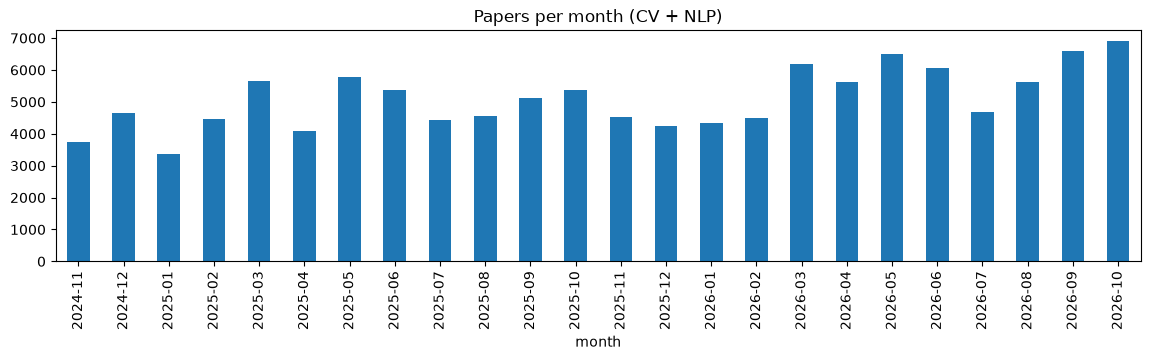

In [7]:
df["month"] = df["submitted"].str[:7]
df.groupby("month").size().plot(kind="bar", figsize=(14, 3), title="Papers per month (CV + NLP)");

In [8]:
df[["arxiv_id", "submitted", "latest_version", "primary_category", "title"]].sample(8, random_state=0)

,arxiv_id,submitted,latest_version,primary_category,title
65534,2601.01312,2026-01-01,2026-01-04,cs.CV,VReID-XFD: Video-based Person Re-identificatio...
3322,2411.17943,2024-11-01,2024-11-26,cs.CL,Evaluating Generative AI-Enhanced Content: A C...
113665,2609.31678,2026-09-01,2026-09-16,cs.LG,When Keywords Drop but Classifiers Hold: Soft ...
56766,2511.01287,2025-11-01,2026-09-07,cs.CL,"""Give a Positive Review Only"": An Early Invest..."
23219,2504.07228,2025-04-01,2025-05-22,cs.CL,ConceptCarve: Dynamic Realization of Evidence
122016,2610.38109,2026-10-01,2026-10-28,cs.SD,Who Called? V33DA: A Physically Verified Multi...
41296,2507.22926,2025-07-01,2025-07-23,cs.CL,Multi-Relation Extraction in Entity Pairs usin...
99624,2607.06008,2026-07-01,2026-08-17,cs.AI,PolyWorkBench: Benchmarking LLM Agents for Cro...


Next: `02_chunk_embed_index.ipynb`.